<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%BF%D1%80%D0%BE%D0%B4%D0%B2%D0%B8%D0%BD%D1%83%D1%82%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%961.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
%pip install -q ucimlrepo deap

import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

from deap import base, creator, tools, algorithms

warnings.filterwarnings('ignore')


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: /private/tmp/claude-501/-Users-yehoryevtushenko-Downloads----------20261123/5134895f-8036-4905-a6c7-e87230bab15e/scratchpad/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Завдання 1. Дані, розбиття та baseline

> Відтворити повний pipeline та отримати baseline для всіх 30 ознак.

In [ ]:
dataset = fetch_ucirepo(id=17)

X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()
y = y.map({"B": 0, "M": 1})

print("X shape:", X.shape)
print("Class distribution:")
print(y.value_counts())
print("\nMissing values:", X.isna().sum().sum())
print("\nFirst rows:")
print(X.head())

X shape: (569, 30)
Class distribution:
Diagnosis
0    357
1    212
Name: count, dtype: int64

Missing values: 0

First rows:
   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
0      0.3001          0.14710     0.2419             0.07871  ...    25.38   
1      0.0869          0.07017     0.1812             0.05667  ...    24.99   
2      0.1974          0.12790     0.2069             0.05999  ...    23.57   
3      0.2414          0.10520     0.2597             0.09744  ...    14.91   
4      0.1980          0.10430     0.1809            

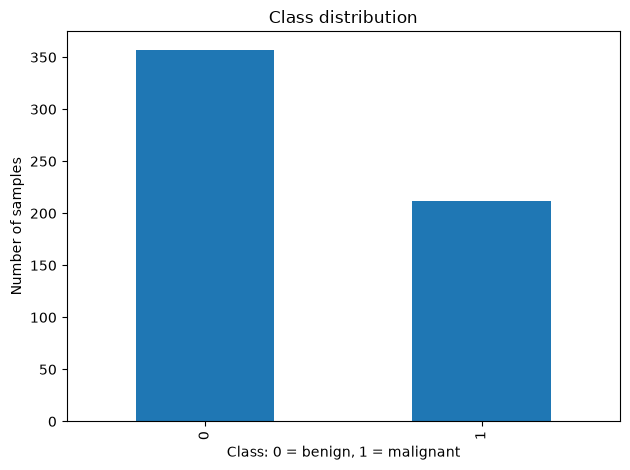

                          mean         std        min         max
radius1              14.127292    3.524049    6.98100    28.11000
texture1             19.289649    4.301036    9.71000    39.28000
perimeter1           91.969033   24.298981   43.79000   188.50000
area1               654.889104  351.914129  143.50000  2501.00000
smoothness1           0.096360    0.014064    0.05263     0.16340
compactness1          0.104341    0.052813    0.01938     0.34540
concavity1            0.088799    0.079720    0.00000     0.42680
concave_points1       0.048919    0.038803    0.00000     0.20120
symmetry1             0.181162    0.027414    0.10600     0.30400
fractal_dimension1    0.062798    0.007060    0.04996     0.09744
Діапазон середніх значень ознак: 0.0037949038664323374 - 880.5831282952548
Відношення найбільшого середнього до найменшого: 232043.59301019873


In [ ]:
y.value_counts().plot(kind="bar")
plt.xlabel("Class: 0 = benign, 1 = malignant")
plt.ylabel("Number of samples")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

stats = X.describe().T[["mean", "std", "min", "max"]]
print(stats.head(10))
print("Діапазон середніх значень ознак:", stats["mean"].min(), "-", stats["mean"].max())
print("Відношення найбільшого середнього до найменшого:", stats["mean"].max() / stats["mean"].min())

Набір містить 569 спостережень і 30 числових ознак без пропущених значень. Класи не збалансовані: 357 доброякісних (B, клас 0, 62.7%) і 212 злоякісних (M, клас 1, 37.3%), тому використовується Balanced Accuracy, яка усереднює повноту за обома класами. Масштаби ознак дуже різні: середні значення лежать від 0.004 до 880 (відношення понад 200 000), наприклад `area1` має середнє 655 і стандартне відхилення 352, а `smoothness1` середнє 0.096 і відхилення 0.014. Стандартизація (`StandardScaler`) потрібна, бо логістична регресія з регуляризацією накладає штраф на ваги однаково, тому ознаки з великими числовими значеннями домінували б, а розбіжність масштабів ускладнює збіжність оптимізатора. Після стандартизації кожна ознака має середнє 0 і відхилення 1.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000, random_state=42))
])

baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

baseline_bacc = balanced_accuracy_score(y_test, pred)

print("Baseline balanced accuracy:", baseline_bacc)
print(classification_report(y_test, pred, digits=4))
print("Confusion matrix:")
print(confusion_matrix(y_test, pred))

(455, 30) (114, 30)
Baseline balanced accuracy: 0.9573412698412699
              precision    recall  f1-score   support

           0     0.9595    0.9861    0.9726        72
           1     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114

Confusion matrix:
[[71  1]
 [ 3 39]]


Baseline на всіх 30 ознаках дає Balanced Accuracy 0.9573 на тесті (accuracy 0.9649; 114 об'єктів у тесті, 20%) і 0.9695 на крос-валідації навчальної частини. Матриця помилок: 71 з 72 доброякісних і 39 з 42 злоякісних класифіковано правильно (1 хибнопозитивний і 3 пропущені злоякісні). Це контрольний результат, із яким порівнюються всі методи відбору ознак.

# Завдання 2. Генетичний алгоритм відбору ознак

> Реалізувати Genetic Algorithm для feature selection.

In [ ]:
N_FEATURES = X_train.shape[1]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=42))
    ])

def cv_bacc(mask):
    mask = np.array(mask, dtype=bool)
    scores = cross_val_score(make_model(), X_train.loc[:, mask], y_train, cv=cv, scoring="balanced_accuracy")
    return scores.mean()

def test_bacc(mask):
    mask = np.array(mask, dtype=bool)
    model = make_model().fit(X_train.loc[:, mask], y_train)
    return balanced_accuracy_score(y_test, model.predict(X_test.loc[:, mask]))

def fitness_value(mask, lam):
    mask = np.array(mask, dtype=bool)
    if mask.sum() == 0:
        return -1.0
    return cv_bacc(mask) - lam * mask.sum() / N_FEATURES

Fitness-функція відповідає формулі з теорії: Fitness = Balanced Accuracy − λ · (N_selected / N_all). Balanced Accuracy усереднюється за 5-кратною стратифікованою крос-валідацією лише на навчальній частині, тестова вибірка в оптимізації не використовується. Порожня підмножина ознак отримує fitness −1. Паралельність `n_jobs=-1` з теорії вимкнена, бо для таких малих даних накладні витрати на запуск процесів перевищують виграш.

In [ ]:
if not hasattr(creator, "FitnessMax"):
    creator.create("FitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMax)

def run_ga(seed=42, pop_size=40, n_gen=25, cxpb=0.8, mutpb=0.2, lam=0.02, indpb=0.05, verbose=False):
    random.seed(seed)
    np.random.seed(seed)
    counter = [0]

    def evaluate_individual(individual):
        counter[0] += 1
        return (fitness_value(individual, lam),)

    toolbox = base.Toolbox()
    toolbox.register("attr_bool", random.randint, 0, 1)
    toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=N_FEATURES)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", evaluate_individual)
    toolbox.register("mate", tools.cxTwoPoint)
    toolbox.register("mutate", tools.mutFlipBit, indpb=indpb)
    toolbox.register("select", tools.selTournament, tournsize=3)

    population = toolbox.population(n=pop_size)
    hall_of_fame = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats.register("avg", np.mean)
    stats.register("max", np.max)
    stats.register("min", np.min)

    start = time.time()
    population, logbook = algorithms.eaSimple(population, toolbox, cxpb=cxpb, mutpb=mutpb, ngen=n_gen,
                                              stats=stats, halloffame=hall_of_fame, verbose=verbose)
    elapsed = time.time() - start
    mask = np.array(hall_of_fame[0], dtype=bool)
    return {'mask': mask, 'fitness': hall_of_fame[0].fitness.values[0], 'cv': cv_bacc(mask), 'test': test_bacc(mask),
            'n': int(mask.sum()), 'time': elapsed, 'evals': counter[0], 'logbook': logbook,
            'population': population, 'lam': lam, 'pop': pop_size, 'mutpb': mutpb, 'seed': seed}

POP_SIZE = 40
N_GENERATIONS = 25
CXPB = 0.8
MUTPB = 0.2
LAMBDA = 0.02

ga_main = run_ga(seed=42, pop_size=POP_SIZE, n_gen=N_GENERATIONS, cxpb=CXPB, mutpb=MUTPB, lam=LAMBDA, verbose=True)
best_mask = ga_main['mask']
selected_features = X.columns[best_mask].tolist()

print("Best fitness:", ga_main['fitness'])
print("Selected features:", len(selected_features), "/", N_FEATURES)
print(selected_features)
print("Кількість викликів fitness:", ga_main['evals'], ", час:", round(ga_main['time'], 1), "с")

gen	nevals	avg     	max     	min     
0  	40    	0.947749	0.961874	0.925123


1  	33    	0.95386 	0.96212 	0.93711 


2  	34    	0.956121	0.964815	0.945934


3  	31    	0.957436	0.965482	0.942846


4  	35    	0.957098	0.966669	0.94915 


5  	34    	0.960501	0.966669	0.948355


... (16 outputs left out)

22 	32    	0.966315	0.970324	0.95367 


23 	37    	0.967847	0.970324	0.9596  


24 	36    	0.968653	0.970324	0.958266


25 	34    	0.969157	0.970324	0.9596  
Best fitness: 0.9703240454076368
Selected features: 11 / 30
['radius1', 'area1', 'smoothness1', 'area2', 'smoothness2', 'compactness2', 'fractal_dimension2', 'texture3', 'area3', 'concave_points3', 'symmetry3']
Кількість викликів fitness: 898 , час: 18.6 с


Генетичний алгоритм з параметрами з теорії (популяція 40, 25 поколінь, crossover 0.8, mutation 0.2, λ = 0.02, seed 42) залишив 11 ознак із 30: `radius1`, `area1`, `smoothness1`, `area2`, `smoothness2`, `compactness2`, `fractal_dimension2`, `texture3`, `area3`, `concave_points3`, `symmetry3`. Найкращий fitness 0.9703, що відповідає CV Balanced Accuracy 0.9777 за штрафу 0.02 · 11/30 = 0.0073. Усього виконано 898 обчислень fitness за 18.6 с. Кількість оцінок менша за 40 · 25 = 1000, бо `eaSimple` повторно оцінює лише тих індивідів, які змінились після схрещування чи мутації.

# Завдання 3. Графік збіжності

> Побудувати графік збіжності fitness.

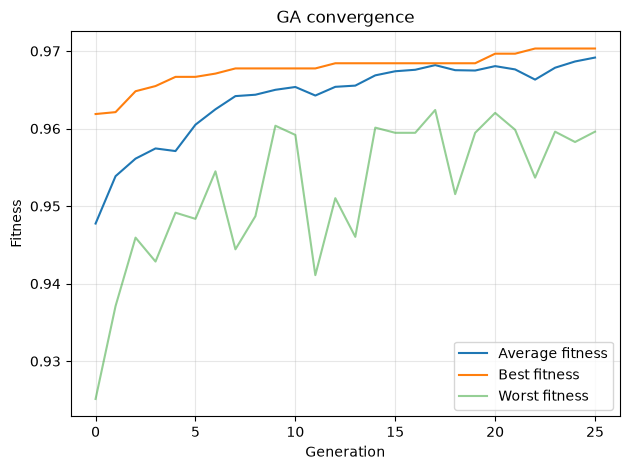

Найкращий fitness: початковий 0.9619 , фінальний 0.9703 , досягнуто в поколінні 22
Різниця між середнім і найкращим fitness: на початку 0.0141 , наприкінці 0.0012


In [ ]:
logbook = ga_main['logbook']
gen = logbook.select("gen")
avg_fit = logbook.select("avg")
max_fit = logbook.select("max")
min_fit = logbook.select("min")

plt.plot(gen, avg_fit, label="Average fitness")
plt.plot(gen, max_fit, label="Best fitness")
plt.plot(gen, min_fit, label="Worst fitness", alpha=0.5)
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.title("GA convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

first_best = next(g for g, v in zip(gen, max_fit) if v == max_fit[-1])
print("Найкращий fitness: початковий", round(max_fit[0], 4), ", фінальний", round(max_fit[-1], 4), ", досягнуто в поколінні", first_best)
print("Різниця між середнім і найкращим fitness: на початку", round(max_fit[0] - avg_fit[0], 4),
      ", наприкінці", round(max_fit[-1] - avg_fit[-1], 4))

Найкращий fitness зріс з 0.9621 у початковій популяції до 0.9703 і досягнув фінального значення в 22-му поколінні: спочатку швидке покращення (приблизно 0.9667 до 4-го покоління, 0.9684 до 14-го), потім плато. Середній fitness популяції зростав з 0.9539 до 0.9692, а різниця між найкращим і середнім скоротилась з 0.0141 до 0.0012, тобто популяція зблизилась до найкращого рішення і втратила різноманіття. Кількість ознак алгоритм скоротив з приблизно 15 (половина з 30 у випадковій початковій популяції) до 11. Останнє покращення відбулось у 22-му поколінні, лише за три покоління до кінця, тому стверджувати, що 25 поколінь достатньо для повної збіжності, можна обережно: приріст на плато малий (порядку 0.001), але повністю виключати подальше покращення не можна.

# Фінальне тестування знайденої підмножини

In [ ]:
final_model = make_model()
final_model.fit(X_train[selected_features], y_train)
pred_ga = final_model.predict(X_test[selected_features])
ga_bacc = balanced_accuracy_score(y_test, pred_ga)

print("All features:", X_train.shape[1])
print("Selected features:", len(selected_features))
print("Baseline BAcc:", baseline_bacc)
print("GA BAcc:", ga_bacc)
print(classification_report(y_test, pred_ga, digits=4))
print(confusion_matrix(y_test, pred_ga))

All features: 30
Selected features: 11
Baseline BAcc: 0.9573412698412699
GA BAcc: 0.9692460317460317
              precision    recall  f1-score   support

           0     0.9726    0.9861    0.9793        72
           1     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114

[[71  1]
 [ 2 40]]


Знайдена підмножина з 11 ознак дає Balanced Accuracy 0.9692 на тесті проти 0.9573 для всіх 30 ознак, accuracy 0.9737 проти 0.9649: помилок стало на одну менше (1 хибнопозитивний і 2 пропущені злоякісні замість 1 і 3). Тобто якість збережена (навіть дещо вища) при використанні 37% ознак. Але різниця дорівнює одному об'єкту із 42 злоякісних у тесті, що відповідає приблизно 1.2 п.п. Balanced Accuracy, тому вважати її доказом переваги не можна.

# Завдання 4. Обов'язкові експерименти

> Провести всі п'ять обов'язкових експериментів з розділу 13.

> 1. Вплив штрафу λ: λ = 0; 0.01; 0.02; 0.05; 0.10. Що проаналізувати: BAcc, кількість ознак, fitness.
> 2. Розмір популяції: 20; 40; 80. Що проаналізувати: якість, стабільність, час.
> 3. Mutation probability: наприклад 0.05; 0.20; 0.40. Що проаналізувати: збіжність і різноманіття.
> 4. Повторні запуски: не менше 5 random seeds. Що проаналізувати: середнє ± std BAcc та число ознак.
> 5. GA vs Random Search: однаковий бюджет оцінювань. Що проаналізувати: чи дає GA систематичну перевагу.

In [ ]:
runs = {}

def get_run(lam=0.02, pop=40, mutpb=0.2, seed=0):
    key = (lam, pop, mutpb, seed)
    if key not in runs:
        runs[key] = run_ga(seed=seed, pop_size=pop, n_gen=N_GENERATIONS, cxpb=CXPB, mutpb=mutpb, lam=lam)
    return runs[key]

def aggregate(results):
    return {
        'fitness': f"{np.mean([r['fitness'] for r in results]):.4f} ± {np.std([r['fitness'] for r in results]):.4f}",
        'BAcc CV': f"{np.mean([r['cv'] for r in results]):.4f} ± {np.std([r['cv'] for r in results]):.4f}",
        'BAcc test': f"{np.mean([r['test'] for r in results]):.4f} ± {np.std([r['test'] for r in results]):.4f}",
        'ознак': f"{np.mean([r['n'] for r in results]):.1f} ± {np.std([r['n'] for r in results]):.1f}",
        'час, с': round(np.mean([r['time'] for r in results]), 1),
    }

SEEDS3 = [0, 1, 2]

# Експеримент 1. Вплив штрафу λ

In [ ]:
exp1 = {}
for lam in [0.0, 0.01, 0.02, 0.05, 0.10]:
    exp1[f"λ = {lam}"] = aggregate([get_run(lam=lam, seed=s) for s in SEEDS3])
print(pd.DataFrame(exp1).T.to_string())

                  fitness          BAcc CV        BAcc test       ознак час, с
λ = 0.0   0.9798 ± 0.0007  0.9798 ± 0.0007  0.9620 ± 0.0103  17.3 ± 2.1   18.5
λ = 0.01  0.9769 ± 0.0013  0.9818 ± 0.0021  0.9603 ± 0.0056  14.7 ± 2.9   18.1
λ = 0.02  0.9703 ± 0.0017  0.9783 ± 0.0017  0.9540 ± 0.0145  12.0 ± 0.0   17.9
λ = 0.05  0.9636 ± 0.0009  0.9747 ± 0.0017  0.9557 ± 0.0175   6.7 ± 1.2   17.3
λ = 0.1   0.9563 ± 0.0039  0.9730 ± 0.0039  0.9368 ± 0.0078   5.0 ± 0.0   16.7


Зі збільшенням λ кількість ознак монотонно зменшується: 17.3 при λ = 0, 14.7 (0.01), 12.0 (0.02), 6.7 (0.05) і 5.0 (0.10). CV Balanced Accuracy при цьому змінюється слабо: від 0.980 – 0.982 (λ = 0 та 0.01) до 0.973 при λ = 0.10, тобто скорочення з 17 до 5 ознак коштує приблизно 0.7 п.п. Fitness зменшується разом з ростом штрафу (0.980, 0.977, 0.970, 0.964, 0.956), що очікувано, бо в ньому віднімається штраф. Навіть при λ = 0 GA вибирає не всі 30, а в середньому 17 ознак, імовірно, тому що частина ознак не додає якості крос-валідаційній моделі. Точність на тесті найнижча при λ = 0.10 (0.937 проти 0.954 – 0.962), але розкид між запусками на тесті (до ± 0.017) порівнянний з цими різницями, тож це лише натяк на втрату якості при надто сильному штрафі. Для практики розумним компромісом виглядає λ = 0.02 – 0.05.

# Експеримент 2. Розмір популяції

In [ ]:
exp2 = {}
for pop in [20, 40, 80]:
    exp2[f"популяція {pop}"] = aggregate([get_run(pop=pop, seed=s) for s in SEEDS3])
print(pd.DataFrame(exp2).T.to_string())

                      fitness          BAcc CV        BAcc test       ознак час, с
популяція 20  0.9691 ± 0.0031  0.9769 ± 0.0025  0.9683 ± 0.0056  11.7 ± 0.9    8.8
популяція 40  0.9703 ± 0.0017  0.9783 ± 0.0017  0.9540 ± 0.0145  12.0 ± 0.0   17.9
популяція 80  0.9739 ± 0.0017  0.9806 ± 0.0019  0.9494 ± 0.0148  10.0 ± 0.8   58.8


Із зростанням популяції найкращий fitness зростає: 0.9691 (20), 0.9703 (40), 0.9739 (80), а кількість ознак зменшується (11.7, 12.0, 10.0). Стабільність (std fitness) для 40 і 80 однакова (0.0017), для 20 гірша (0.0031). Час при цьому зростає значно швидше за якість: 8.8, 17.9 і 58.8 с (популяція 80 коштує приблизно втричі більше за популяцію 40 заради приросту fitness 0.0036). Точність на тесті, навпаки, не покращується (0.968, 0.954, 0.949), тобто кращий fitness на крос-валідації не перетворився на кращу якість на незалежних даних, що показує обмеженість оптимізації за крос-валідацією на 455 об'єктах: більший пошук легше підлаштовується під її випадкові розбиття. Для цієї задачі достатньо популяції 20–40.

# Експеримент 3. Ймовірність мутації

                    fitness          BAcc CV        BAcc test       ознак час, с
mutpb 0.05  0.9713 ± 0.0019  0.9791 ± 0.0007  0.9762 ± 0.0000  11.7 ± 2.4   16.8
mutpb 0.2   0.9703 ± 0.0017  0.9783 ± 0.0017  0.9540 ± 0.0145  12.0 ± 0.0   17.9
mutpb 0.4   0.9712 ± 0.0022  0.9777 ± 0.0022  0.9620 ± 0.0127   9.7 ± 0.9   18.3


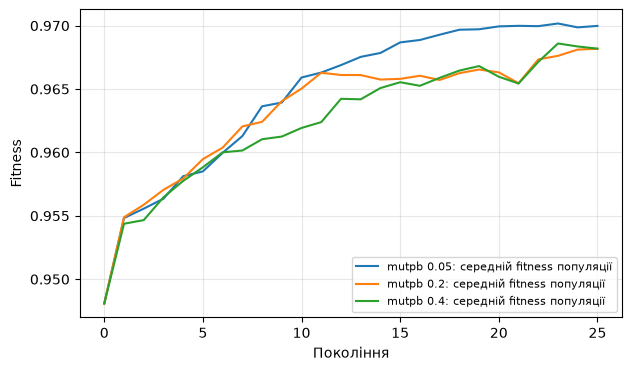

In [ ]:
exp3 = {}
for mutpb in [0.05, 0.2, 0.4]:
    exp3[f"mutpb {mutpb}"] = aggregate([get_run(mutpb=mutpb, seed=s) for s in SEEDS3])
print(pd.DataFrame(exp3).T.to_string())

plt.figure(figsize=(7, 4))
for mutpb in [0.05, 0.2, 0.4]:
    curves = np.array([get_run(mutpb=mutpb, seed=s)['logbook'].select('avg') for s in SEEDS3])
    plt.plot(curves.mean(axis=0), label=f'mutpb {mutpb}: середній fitness популяції')
plt.xlabel('Покоління')
plt.ylabel('Fitness')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

Ймовірність мутації 0.05, 0.20 та 0.40 дає практично однаковий найкращий fitness (0.9713, 0.9703, 0.9712) у межах розкиду між запусками (± 0.002), тож залежність від ймовірності мутації в цьому діапазоні слабка. Помітна лише різниця в кількості ознак: 11.7, 12.0 і 9.7 (при 0.40 алгоритм у середньому залишає менше ознак). Час практично однаковий (17 – 18 с), бо кількість оцінок майже не залежить від ймовірності мутації. На графіку наведено середній fitness популяції за поколіннями для трьох значень mutpb. Тест Balanced Accuracy (0.976, 0.954, 0.962) знову не слідує за fitness і тут лише ілюструє шум оцінки на 114 об'єктах.

# Експеримент 4. Повторні запуски

        fitness  BAcc CV  BAcc test  ознак
seed 0   0.9720   0.9800     0.9643   12.0
seed 1   0.9679   0.9759     0.9643   12.0
seed 2   0.9708   0.9788     0.9335   12.0
seed 3   0.9654   0.9747     0.9573   14.0
seed 4   0.9702   0.9788     0.9762   13.0
{'fitness': '0.9693 ± 0.0024', 'BAcc CV': '0.9777 ± 0.0020', 'BAcc test': '0.9591 ± 0.0142', 'ознак': '12.6 ± 0.8', 'час, с': np.float64(17.6)}


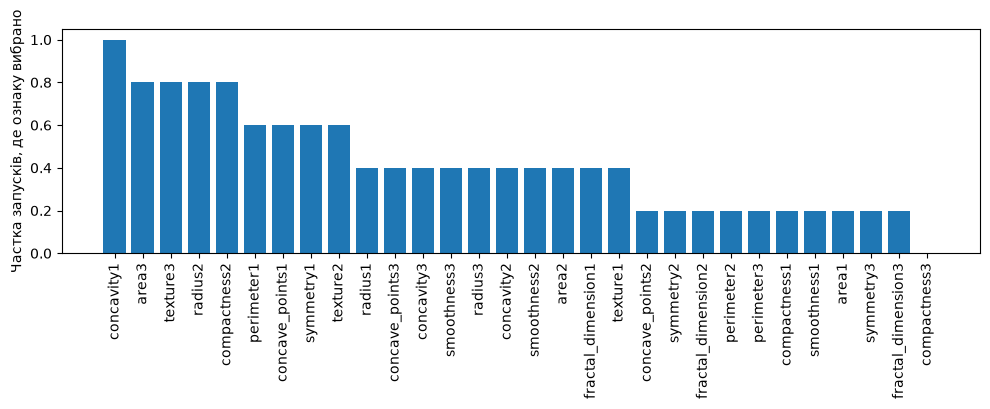

Ознаки, вибрані у всіх 5 запусках: ['concavity1']


In [ ]:
SEEDS5 = [0, 1, 2, 3, 4]
ga_runs = [get_run(seed=s) for s in SEEDS5]
rows = {f"seed {r['seed']}": {'fitness': round(r['fitness'], 4), 'BAcc CV': round(r['cv'], 4),
                              'BAcc test': round(r['test'], 4), 'ознак': r['n']} for r in ga_runs}
print(pd.DataFrame(rows).T.to_string())
print(aggregate(ga_runs))

frequency = np.mean([r['mask'] for r in ga_runs], axis=0)
order = np.argsort(-frequency)
plt.figure(figsize=(10, 4))
plt.bar(range(N_FEATURES), frequency[order])
plt.xticks(range(N_FEATURES), X.columns[order], rotation=90)
plt.ylabel('Частка запусків, де ознаку вибрано')
plt.tight_layout()
plt.show()
print("Ознаки, вибрані у всіх 5 запусках:", X.columns[frequency == 1].tolist())

За 5 seeds базова конфігурація дає fitness 0.9693 ± 0.0024, CV Balanced Accuracy 0.9777 ± 0.0020, Balanced Accuracy на тесті 0.9591 ± 0.0142 і 12.6 ± 0.8 ознаки. Розкид на тесті (від 0.934 до 0.976 для окремих seeds) значно більший за розкид CV, і розкид одного запуску на тесті більший за різницю між baseline (0.957) і середнім GA (0.959), тому висновки з одного запуску ненадійні. Склад підмножин також змінюється між запусками: лише одна ознака, `concavity1`, потрапила у всі 5 підмножин. Частоту вибору інших ознак показано на стовпчиковій діаграмі, але стабільного єдиного оптимального набору немає. Кількість ознак значно стабільніша (12 – 14), ніж їх склад.

# Експеримент 5. GA проти Random Search

In [ ]:
def random_search(seed, budget=POP_SIZE * N_GENERATIONS, lam=LAMBDA):
    rng = np.random.RandomState(seed)
    start = time.time()
    best_mask, best_fit = None, -np.inf
    for _ in range(budget):
        mask = rng.randint(0, 2, size=N_FEATURES).astype(bool)
        f = fitness_value(mask, lam)
        if f > best_fit:
            best_fit, best_mask = f, mask
    return {'mask': best_mask, 'fitness': best_fit, 'cv': cv_bacc(best_mask), 'test': test_bacc(best_mask),
            'n': int(best_mask.sum()), 'time': time.time() - start, 'evals': budget, 'seed': seed}

rs_main = random_search(42)
print("Random Search (seed 42) fitness:", rs_main['fitness'], ", ознак:", rs_main['n'])
print(X.columns[rs_main['mask']].tolist())

rs_runs = [random_search(s) for s in SEEDS5]
print("Кількість викликів fitness: GA", [r['evals'] for r in ga_runs], ", Random Search", rs_runs[0]['evals'])

comparison = pd.DataFrame({'GA': aggregate(ga_runs), 'Random Search': aggregate(rs_runs)}).T
print(comparison.to_string())
print(pd.DataFrame({'GA fitness': [round(r['fitness'], 4) for r in ga_runs],
                    'RS fitness': [round(r['fitness'], 4) for r in rs_runs],
                    'GA ознак': [r['n'] for r in ga_runs], 'RS ознак': [r['n'] for r in rs_runs]},
                   index=[f'seed {s}' for s in SEEDS5]).to_string())

Random Search (seed 42) fitness: 0.9674819401444787 , ознак: 10
['texture1', 'perimeter1', 'area1', 'symmetry1', 'radius2', 'concavity2', 'perimeter3', 'smoothness3', 'concavity3', 'fractal_dimension3']


Кількість викликів fitness: GA [897, 860, 895, 875, 864] , Random Search 1000
                       fitness          BAcc CV        BAcc test       ознак час, с
GA             0.9693 ± 0.0024  0.9777 ± 0.0020  0.9591 ± 0.0142  12.6 ± 0.8   17.6
Random Search  0.9675 ± 0.0010  0.9770 ± 0.0013  0.9492 ± 0.0090  14.2 ± 1.5   29.6
        GA fitness  RS fitness  GA ознак  RS ознак
seed 0      0.9720      0.9682        12        16
seed 1      0.9679      0.9664        12        16
seed 2      0.9708      0.9684        12        13
seed 3      0.9654      0.9684        14        13
seed 4      0.9702      0.9660        13        13


Random Search (1000 випадкових підмножин) дав fitness 0.9675 ± 0.0010 проти 0.9693 ± 0.0024 для GA, а кількість ознак 14.2 ± 1.5 проти 12.6 ± 0.8. GA кращий за fitness у 4 із 5 seeds (у seed 3 Random Search кращий: 0.9684 проти 0.9654), хоча виконує менше оцінок (860 – 897 проти 1000). Різниця (0.0018) менша за розкид між запусками GA (0.0024), тому систематичну перевагу GA для цієї конфігурації можна вважати слабкою, але напрямок усталений: GA знаходить компактніші підмножини, а тестова Balanced Accuracy (0.959 проти 0.949) відрізняється в межах розкиду. Імовірною причиною є мала розмірність задачі (30 ознак): випадковий пошук при бюджеті 1000 оцінок вже знаходить підмножини близької якості.

# Завдання 5. Порівняння GA, Random Search та моделі з усіма ознаками, список ознак найкращої конфігурації

> Порівняти GA, Random Search та модель з усіма ознаками.

> Для найкращої конфігурації показати список вибраних ознак.

In [ ]:
candidates = [r for r in list(runs.values()) + [ga_main] if r['lam'] == 0.02]
best_run = max(candidates, key=lambda r: r['fitness'])
print(f"Найкраща конфігурація за fitness на крос-валідації (λ = 0.02): seed {best_run['seed']}, популяція {best_run['pop']}, "
      f"mutpb {best_run['mutpb']}, fitness {best_run['fitness']:.4f}")
best_features = X.columns[best_run['mask']].tolist()
print("Вибрані ознаки:", len(best_features), "/", N_FEATURES)
for name in best_features:
    print(" ", name)
print("BAcc CV:", round(best_run['cv'], 4), ", BAcc test:", round(best_run['test'], 4))

Найкраща конфігурація за fitness на крос-валідації (λ = 0.02): seed 2, популяція 80, mutpb 0.2, fitness 0.9756
Вибрані ознаки: 11 / 30
  perimeter1
  area1
  smoothness1
  concavity1
  symmetry1
  radius2
  texture2
  compactness2
  fractal_dimension2
  radius3
  texture3
BAcc CV: 0.983 , BAcc test: 0.9335


Серед усіх запусків з λ = 0.02 найвищий fitness за крос-валідацією (0.9756) має запуск з популяцією 80, mutpb 0.2 та seed 2: 11 ознак (`perimeter1`, `area1`, `smoothness1`, `concavity1`, `symmetry1`, `radius2`, `texture2`, `compactness2`, `fractal_dimension2`, `radius3`, `texture3`), CV Balanced Accuracy 0.983. Конфігурацію вибрано лише за крос-валідацією на навчальній вибірці, без перегляду тесту. Її Balanced Accuracy на тесті 0.9335, що нижче за baseline (0.9573) і за інші GA-запуски. Це демонструє, що найкраще значення на CV не гарантує найкращого значення на тесті, коли тест має лише 114 об'єктів.

# Завдання 6. Підсумкова таблиця

> Побудувати підсумкову таблицю: метод, BAcc CV, BAcc test, кількість ознак, частка ознак, час виконання.

In [ ]:
all_mask = np.ones(N_FEATURES, dtype=bool)
start = time.time()
all_cv = cv_bacc(all_mask)
all_time = time.time() - start

rows = [
    ('Усі ознаки (baseline)', all_cv, baseline_bacc, N_FEATURES, all_time),
    ('GA (seed 42)', ga_main['cv'], ga_main['test'], ga_main['n'], ga_main['time']),
    ('Random Search (seed 42)', rs_main['cv'], rs_main['test'], rs_main['n'], rs_main['time']),
    ('GA, середнє за 5 seeds', np.mean([r['cv'] for r in ga_runs]), np.mean([r['test'] for r in ga_runs]),
     np.mean([r['n'] for r in ga_runs]), np.mean([r['time'] for r in ga_runs])),
    ('Random Search, середнє за 5 seeds', np.mean([r['cv'] for r in rs_runs]), np.mean([r['test'] for r in rs_runs]),
     np.mean([r['n'] for r in rs_runs]), np.mean([r['time'] for r in rs_runs])),
    ('GA, найкраща конфігурація', best_run['cv'], best_run['test'], best_run['n'], best_run['time']),
]
summary = pd.DataFrame(rows, columns=['Метод', 'BAcc CV', 'BAcc test', 'Кількість ознак', 'Час, с'])
summary['Частка ознак'] = summary['Кількість ознак'] / N_FEATURES
summary = summary[['Метод', 'BAcc CV', 'BAcc test', 'Кількість ознак', 'Частка ознак', 'Час, с']]
print(summary.round(4).to_string(index=False))

                            Метод  BAcc CV  BAcc test  Кількість ознак  Частка ознак  Час, с
            Усі ознаки (baseline)   0.9695     0.9573             30.0        1.0000  0.0243
                     GA (seed 42)   0.9777     0.9692             11.0        0.3667 18.5774
          Random Search (seed 42)   0.9741     0.9881             10.0        0.3333 63.9262
           GA, середнє за 5 seeds   0.9777     0.9591             12.6        0.4200 17.6286
Random Search, середнє за 5 seeds   0.9770     0.9492             14.2        0.4733 29.6264
        GA, найкраща конфігурація   0.9830     0.9335             11.0        0.3667 34.1646


Усі підмножини зберігають CV Balanced Accuracy на рівні baseline або вище (0.977 – 0.983 проти 0.9695) при використанні 33 – 47% ознак. На тесті результати лежать у діапазоні 0.934 – 0.988 і значною мірою визначаються шумом: наприклад, Random Search (seed 42) має найвищий тест 0.9881, але лише завдяки вдалому збігу, бо його середнє за 5 seeds (0.9492) нижче за GA (0.9591) та baseline (0.9573). Час Random Search для seed 42 (63.9 с) сильно відрізняється від середнього за 5 seeds (29.6 с), тому для порівняння краще брати середній час та кількість оцінок (1000). Baseline має найменший час, бо обчислюється лише один раз, а не тисячу.

# Додаткове завдання підвищеної складності

> Оберіть один із варіантів: (1) замініть Logistic Regression на інший класифікатор і перевірте, чи змінюється оптимальна підмножина ознак; (2) сформулюйте двокритеріальну задачу «максимізувати Balanced Accuracy / мінімізувати кількість ознак» та побудуйте Pareto front; (3) реалізуйте власний цикл Genetic Algorithm без algorithms.eaSimple.

Обрано варіант (3).

                    fitness          BAcc CV        BAcc test       ознак час, с
власний GA  0.9705 ± 0.0021  0.9777 ± 0.0023  0.9563 ± 0.0061  10.8 ± 1.7   19.7
eaSimple    0.9693 ± 0.0024  0.9777 ± 0.0020  0.9591 ± 0.0142  12.6 ± 0.8   17.6
Кількість викликів fitness у власному GA: [990, 990, 990, 990, 990]


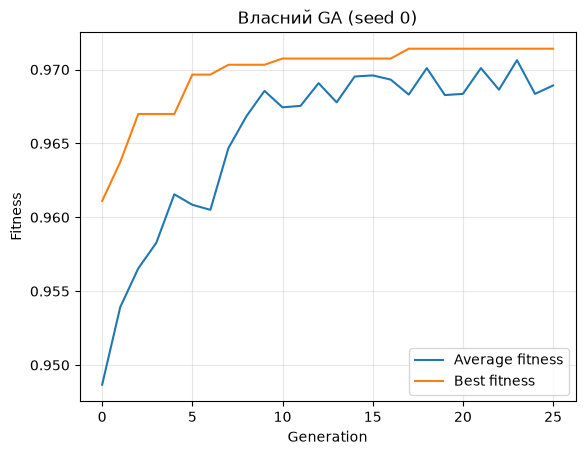

In [ ]:
def own_ga(seed, pop_size=POP_SIZE, n_gen=N_GENERATIONS, cxpb=CXPB, mutpb=MUTPB, indpb=0.05, lam=LAMBDA,
           tournsize=3, elite=2):
    rng = np.random.RandomState(seed)
    start = time.time()
    evals = 0

    def fitness(mask):
        nonlocal evals
        evals += 1
        return fitness_value(mask, lam)

    population = rng.randint(0, 2, size=(pop_size, N_FEATURES))
    fits = np.array([fitness(ind) for ind in population])
    history = [(fits.mean(), fits.max())]
    for _ in range(n_gen):
        order = np.argsort(-fits)
        elites = population[order[:elite]].copy()
        elite_fits = fits[order[:elite]].copy()
        chosen = []
        for _ in range(pop_size - elite):
            contenders = rng.randint(0, pop_size, size=tournsize)
            chosen.append(population[contenders[np.argmax(fits[contenders])]].copy())
        children = np.array(chosen)
        for i in range(0, len(children) - 1, 2):
            if rng.rand() < cxpb:
                a, b = sorted(rng.choice(N_FEATURES, size=2, replace=False))
                tmp = children[i, a:b].copy()
                children[i, a:b] = children[i + 1, a:b]
                children[i + 1, a:b] = tmp
        for i in range(len(children)):
            if rng.rand() < mutpb:
                flips = rng.rand(N_FEATURES) < indpb
                children[i, flips] = 1 - children[i, flips]
        child_fits = np.array([fitness(ind) for ind in children])
        population = np.vstack([elites, children])
        fits = np.concatenate([elite_fits, child_fits])
        history.append((fits.mean(), fits.max()))
    best = population[np.argmax(fits)].astype(bool)
    return {'mask': best, 'fitness': fits.max(), 'cv': cv_bacc(best), 'test': test_bacc(best), 'n': int(best.sum()),
            'time': time.time() - start, 'evals': evals, 'history': history, 'seed': seed}

own_runs = [own_ga(s) for s in SEEDS5]
print(pd.DataFrame({'власний GA': aggregate(own_runs), 'eaSimple': aggregate(ga_runs)}).T.to_string())
print("Кількість викликів fitness у власному GA:", [r['evals'] for r in own_runs])

history = np.array(own_runs[0]['history'])
plt.plot(history[:, 0], label='Average fitness')
plt.plot(history[:, 1], label='Best fitness')
plt.xlabel('Generation')
plt.ylabel('Fitness')
plt.title('Власний GA (seed 0)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Власна реалізація циклу (турнірний відбір розміром 3, двоточкове схрещування з імовірністю 0.8, мутація з імовірністю 0.2 та 0.05 на біт, збереження двох найкращих індивідів (елітизм), 990 оцінок) дає fitness 0.9705 ± 0.0021, CV Balanced Accuracy 0.9777 ± 0.0023, Balanced Accuracy на тесті 0.9563 ± 0.0061 та 10.8 ± 1.7 ознаки. Це збігається з результатами `eaSimple` (0.9693 ± 0.0024, 0.9777, 0.9591 ± 0.0142, 12.6 ± 0.8) у межах розкиду. Елітизм гарантує, що найкращий fitness не знижується від покоління до покоління, а в `eaSimple` цю роль виконує Hall of Fame (без прямого збереження найкращих у популяції). Власний цикл показує, що поведінка алгоритму визначається самими операторами, а не конкретною бібліотекою.

# Висновки

У цьому практикумі ми навчились формулювати відбір ознак як задачу дискретної оптимізації (бінарний вектор довжини 30, fitness = Balanced Accuracy − λ · N_selected/N_all), реалізовувати генетичний алгоритм засобами Python та DEAP, коректно використовувати train/validation/test (fitness лише за крос-валідацією на навчальній частині) і досліджувати збіжність та стабільність стохастичного алгоритму. Метою роботи було ознайомитися з принципами еволюційної оптимізації та дослідити генетичний алгоритм як метод пошуку підмножини інформативних ознак, і її досягнуто.

**Результати.** Модель з усіма 30 ознаками дає Balanced Accuracy 0.957 на тесті. GA знаходить підмножину з 11 – 13 ознак (в середньому 12.6 ± 0.8 за 5 seeds) з CV Balanced Accuracy 0.978 проти 0.970 для всіх ознак і тестовою 0.959 ± 0.014. Тобто якість зберігається при скороченні кількості ознак приблизно в 2.4 раза. Збільшення λ від 0 до 0.10 зменшує кількість ознак з 17 до 5 ціною приблизно 0.7 п.п. CV-якості. Збільшення популяції та зміна ймовірності мутації (0.05 – 0.4) практично не змінюють якість в межах розкиду запусків, а час при популяції 80 зростає втричі. GA за fitness перевершує Random Search з однаковим бюджетом лише на 0.0018 (0.9693 проти 0.9675, краще у 4 із 5 seeds), що менше за розкид між запусками.

**Чи виправдане використання еволюційного пошуку.** Для цієї задачі лише частково. Відбір ознак корисний, бо дозволяє скоротити модель втричі без втрати якості, але перевага GA над випадковим пошуком мала, а різниця в якості на тесті (114 об'єктів, одна помилка дорівнює близько 1.2 п.п.) і розкид між запусками (± 0.014) не дозволяють підтвердити перевагу над baseline. Склад підмножин нестабільний (лише `concavity1` вибрано в усіх 5 запусках), тож інтерпретувати конкретний набір як єдиний «найкращий» не можна. Найкраща за CV конфігурація (популяція 80) показала найгірший тест (0.9335), тому вибір конфігурації за один запуск чи за CV на невеликій вибірці ненадійний. Обмеження експерименту: невелика вибірка, один розбиття train/test, 3 seeds для експериментів 1 – 3, лише логістична регресія в якості класифікатора.

# Контрольні питання

**1. Що таке еволюційна оптимізація і чим вона відрізняється від градієнтної?**

Еволюційна оптимізація це ітеративне покращення популяції кандидатних рішень за допомогою операторів відбору, схрещування та мутації, без перевірки всіх можливих варіантів. Вона працює з дискретними просторами (у цій роботі це 2^30 підмножин ознак, понад мільярд варіантів, для яких повний перебір нераціональний), потребує лише значення fitness-функції для кожного рішення і не використовує її похідних. Градієнтна оптимізація, навпаки, рухається одним рішенням у напрямку градієнта цільової функції, тому потребує її диференційованості та неперервних параметрів. Оскільки еволюційний алгоритм випадковий, його результат залежить від початкового стану генератора випадкових чисел.

**2. Що в даній роботі є індивідом, геном і популяцією?**

Індивід це бінарний вектор довжини 30, що задає одну підмножину ознак: 1 означає, що ознаку використано, 0 що виключено (наприклад, [1, 0, 1, 0, ...]). Геном індивіда складається з 30 бітів, кожен біт відповідає одній ознаці. Популяція це набір таких індивідів (у базовій конфігурації їх 40), який змінюється від покоління до покоління.

**3. Для чого потрібна fitness-функція?**

Fitness-функція оцінює якість кожного індивіда і визначає, які з них будуть вибрані як основа наступного покоління. У роботі Fitness = Balanced Accuracy − λ · (N_selected / N_all): перший доданок винагороджує якість класифікації (середнє за 5-кратною крос-валідацією на навчальній вибірці), другий штрафує за велику кількість ознак.

**4. Яку роль відіграють crossover та mutation?**

Crossover обмінює частини двох батьківських рішень (у роботі двоточковий `cxTwoPoint`), поєднуючи фрагменти вдалих підмножин ознак. Mutation випадково змінює окремі біти (`mutFlipBit`), що підтримує різноманіття популяції та дозволяє знаходити нові комбінації ознак, яких немає в поточній популяції.

**5. Що означає exploration–exploitation trade-off для Genetic Algorithm?**

Exploration це дослідження нових областей простору пошуку, яке забезпечують мутація та велика популяція, а exploitation це поглиблений пошук навколо вже знайдених добрих рішень, який забезпечують відбір кращих індивідів, турнірний відбір і елітизм. Надто сильне дослідження перетворює пошук на випадковий, а надто сильна експлуатація призводить до втрати різноманіття та застрягання в локальному оптимумі, тому потрібен баланс, який регулюється розміром популяції, ймовірністю мутації та тиском відбору.

**6. Чому test set не можна використовувати всередині fitness-функції?**

Якщо тестову вибірку використати в fitness, алгоритм підбиратиме підмножину ознак саме під неї, тож результат на ній стане завищеною оцінкою і перестане відображати якість на нових даних. Тому тестова вибірка відкладається один раз і використовується лише для фінальної перевірки, а fitness оцінюється лише на навчальній частині за Stratified K-Fold крос-валідацією.

**7. Навіщо до fitness додано штраф за кількість ознак?**

Якщо оптимізувати лише точність, алгоритм може залишити майже всі ознаки, бо додаткові ознаки рідко погіршують крос-валідаційну якість. Штраф λ · (N_selected / N_all) винагороджує скорочення кількості ознак, тож алгоритм шукає компроміс між якістю моделі та кількістю використаних ознак.

**8. Як збільшення λ впливає на очікуваний розв'язок?**

Чим більше λ, тим сильніше алгоритм прагне скоротити кількість ознак, тож очікується, що знайдена підмножина буде меншою, а при надто великому λ це може призвести до втрати якості класифікації. При λ = 0 штрафу немає, і алгоритм оптимізує лише якість.

**9. Чому один запуск стохастичного алгоритму недостатній для надійного висновку?**

Результат генетичного алгоритму залежить від випадкової початкової популяції та випадкових операторів, тому два запуски з різними random seeds можуть дати різні підмножини ознак і різну якість. Щоб відрізнити систематичний ефект від випадкового, потрібно виконати кілька запусків (не менше 5 seeds) і порівнювати середнє ± стандартне відхилення.

**10. Навіщо порівнювати GA з Random Search при однаковому computational budget?**

Random Search це простий контрольний метод, який перевіряє ту саму кількість випадкових підмножин без еволюційних операторів. Якщо GA при однаковому бюджеті оцінювань не дає кращого fitness, то його складність не виправдана, а перевага GA над моделлю з усіма ознаками сама по собі не доводить цінність еволюційного пошуку.